[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/gianni04/spy-delta-hedging/blob/main/delta_hedging.ipynb)

# Delta hedging SPY options

A short option that is delta hedged every day makes or loses money depending on one thing:
was the volatility it was sold at (implied) higher or lower than the volatility that actually
happened (realised)?

1. **Simulation:** check this on simulated prices, and see the effect of hedging frequency and costs.
2. **Real data:** sell a one-month at-the-money SPY straddle every month from 2010 to 2025,
   hedge it daily at the close, and compare the P&L with implied minus realised volatility.

In [1]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
from scipy.stats import norm

rng = np.random.default_rng(42)

## Black-Scholes

European price and delta with a dividend yield `q`. The straddle is one call plus one put at the
same strike.

In [2]:
def bs(S, K, T, r, q, sigma, kind):
    d1 = (np.log(S / K) + (r - q + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    if kind == "call":
        price = S * np.exp(-q * T) * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)
        delta = np.exp(-q * T) * norm.cdf(d1)
    else:
        price = K * np.exp(-r * T) * norm.cdf(-d2) - S * np.exp(-q * T) * norm.cdf(-d1)
        delta = -np.exp(-q * T) * norm.cdf(-d1)
    return price, delta

def straddle(S, K, T, r, q, sigma):
    c, dc = bs(S, K, T, r, q, sigma, "call")
    p, dp = bs(S, K, T, r, q, sigma, "put")
    return c + p, dc + dp

## The hedging engine

Sell the straddle, hold its delta in shares, rebalance at every date, pay a cost on each share
trade, receive dividends on the shares held, and earn or pay interest on cash. At expiry, pay the
straddle payoff and sell the shares. The result is the P&L of the hedged position. `S` can hold
one price path or many (one per row).

In [3]:
def hedge_short_straddle(S, K, T, r, q, sigma, divs=None, cost=0.0):
    S = np.atleast_2d(S)
    n = S.shape[1] - 1
    dt = T / n
    divs = np.zeros(n + 1) if divs is None else divs
    premium, delta = straddle(S[:, 0], K, T, r, q, sigma)
    shares = delta
    cash = premium - shares * S[:, 0] - cost * np.abs(shares) * S[:, 0]
    for i in range(1, n):
        cash = cash * np.exp(r * dt) + shares * divs[i]
        _, delta = straddle(S[:, i], K, T - i * dt, r, q, sigma)
        cash -= (delta - shares) * S[:, i] + cost * np.abs(delta - shares) * S[:, i]
        shares = delta
    cash = cash * np.exp(r * dt) + shares * divs[n]
    pnl = cash + shares * S[:, n] - np.abs(S[:, n] - K)
    return pnl if len(pnl) > 1 else pnl[0]

## 1. Simulation

Stock price S = 100, one-month ATM straddle, true (realised) volatility 20%, 5,000 paths.

In [4]:
def gbm(S0, sigma, T, n, paths, r=0.0):
    z = rng.standard_normal((paths, n))
    steps = (r - 0.5 * sigma**2) * (T / n) + sigma * np.sqrt(T / n) * z
    return S0 * np.exp(np.hstack([np.zeros((paths, 1)), np.cumsum(steps, axis=1)]))

T, r, real_vol = 21 / 252, 0.03, 0.20
rows = []
for n in [1, 5, 21, 63, 252]:
    paths = gbm(100, real_vol, T, n, 5000, r)
    for implied in [0.20, 0.25]:
        for cost in [0.0, 0.001]:
            pnl = hedge_short_straddle(paths, 100, T, r, 0.0, implied, cost=cost)
            rows.append({"rebalances": n, "implied vol": implied, "cost": cost,
                         "mean P&L": pnl.mean(), "std P&L": pnl.std()})
sim = pd.DataFrame(rows)

gap = straddle(100, 100, T, r, 0, 0.25)[0] - straddle(100, 100, T, r, 0, 0.20)[0]
print(f"price at 25% vol minus price at 20% vol: {gap:.3f}")
print(sim.round(3).to_string(index=False))

price at 25% vol minus price at 20% vol: 1.149
 rebalances  implied vol  cost  mean P&L  std P&L
          1         0.20 0.000     0.026    3.510
          1         0.20 0.001     0.020    3.510
          1         0.25 0.000     1.177    3.510
          1         0.25 0.001     1.172    3.510
          5         0.20 0.000    -0.034    1.702
          5         0.20 0.001    -0.160    1.721
          5         0.25 0.000     1.113    1.733
          5         0.25 0.001     1.001    1.750
         21         0.20 0.000    -0.019    0.858
         21         0.20 0.001    -0.308    0.885
         21         0.25 0.000     1.129    0.934
         21         0.25 0.001     0.871    0.930
         63         0.20 0.000    -0.002    0.513
         63         0.20 0.001    -0.513    0.564
         63         0.25 0.000     1.159    0.641
         63         0.25 0.001     0.704    0.588
        252         0.20 0.000     0.006    0.261
        252         0.20 0.001    -1.017    0.464
   

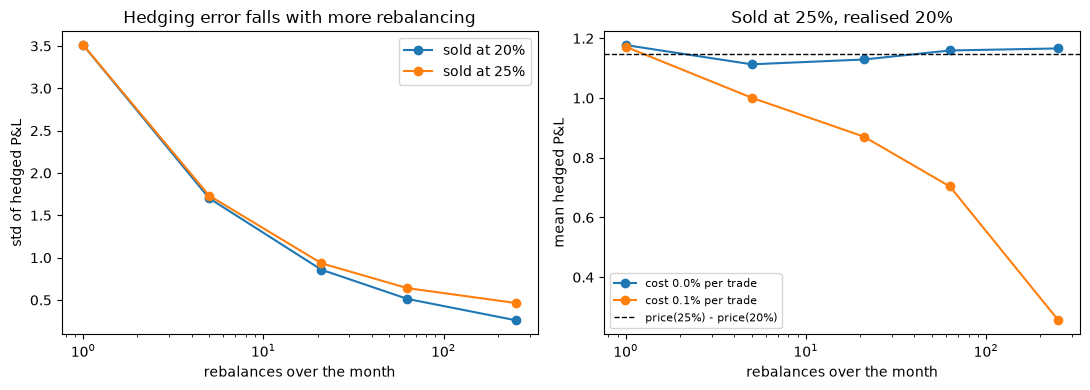

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
no_cost = sim[sim["cost"] == 0]
for implied, g in no_cost.groupby("implied vol"):
    axes[0].plot(g["rebalances"], g["std P&L"], marker="o", label=f"sold at {implied:.0%}")
axes[0].set_xscale("log")
axes[0].set_xlabel("rebalances over the month")
axes[0].set_ylabel("std of hedged P&L")
axes[0].set_title("Hedging error falls with more rebalancing")
axes[0].legend()

g = sim[sim["implied vol"] == 0.25]
for cost, gg in g.groupby("cost"):
    axes[1].plot(gg["rebalances"], gg["mean P&L"], marker="o", label=f"cost {cost:.1%} per trade")
axes[1].axhline(gap, ls="--", color="k", lw=1, label="price(25%) - price(20%)")
axes[1].set_xscale("log")
axes[1].set_xlabel("rebalances over the month")
axes[1].set_ylabel("mean hedged P&L")
axes[1].set_title("Sold at 25%, realised 20%")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

What the simulation shows:

- Sold at the true volatility (20%), the hedged P&L averages zero; its spread shrinks as the hedge
  is rebalanced more often (roughly with 1 / square root of the number of rebalances).
- Sold at 25% while the market realises 20%, the seller keeps the price difference between the
  two volatilities, whatever the hedging frequency.
- Transaction costs grow with the number of trades, so hedging more often is not free.

## 2. Real data: SPY 2010-2025

- **Implied volatility:** VIX. VIX is the 30-day variance swap rate of the S&P 500, which is usually
  a bit above the at-the-money option volatility because of the skew. A second run uses 0.8 x VIX
  as a more realistic at-the-money level.
- **Rate:** 13-week T-bill (^IRX). **Dividends:** actual SPY dividends, received on the shares held;
  the option is priced with the trailing 12-month dividend yield.
- **Trades:** every 21 trading days, sell a 21-day ATM straddle on SPY, hedge daily at the close,
  1 bp cost per share trade. Trades do not overlap.
- SPY options are American; they are priced as European here, which matters little for a one-month
  ATM straddle.

In [6]:
spy = yf.Ticker("SPY").history(start="2009-01-01", end="2026-01-01", auto_adjust=False)
spy.index = spy.index.tz_localize(None).normalize()
px = yf.download(["^VIX", "^IRX"], start="2009-01-01", end="2026-01-01", progress=False)["Close"]
data = pd.DataFrame({
    "S": spy["Close"],
    "div": spy["Dividends"],
    "vix": px["^VIX"] / 100,
    "rate": px["^IRX"] / 100,
}).dropna(subset=["S"])
data[["vix", "rate"]] = data[["vix", "rate"]].ffill()
data["q"] = data["div"].rolling(252).sum() / data["S"]
data = data.loc["2010-01-01":].dropna()
print(len(data), "trading days,", data.index[0].date(), "to", data.index[-1].date())

4024 trading days, 2010-01-04 to 2025-12-31


In [7]:
def run(vol_scale=1.0, days=21, cost=0.0001):
    rows = []
    for start in range(0, len(data) - days, days):
        d = data.iloc[start:start + days + 1]
        S, K, T = d["S"].values, d["S"].iloc[0], days / 252
        implied = d["vix"].iloc[0] * vol_scale
        pnl = hedge_short_straddle(S, K, T, d["rate"].iloc[0], d["q"].iloc[0], implied,
                                   divs=d["div"].values, cost=cost)
        realised = np.log(S[1:] / S[:-1]).std(ddof=0) * np.sqrt(252)
        rows.append({"date": d.index[0], "implied": implied, "realised": realised,
                     "pnl %": pnl / K * 100})
    return pd.DataFrame(rows).set_index("date")

trades = run()
trades_atm = run(vol_scale=0.8)

for name, t in [("sold at VIX", trades), ("sold at 0.8 x VIX", trades_atm)]:
    print(f"{name:18s} trades {len(t)}, mean P&L {t['pnl %'].mean():+.2f}% of spot, "
          f"win rate {(t['pnl %'] > 0).mean():.0%}, worst {t['pnl %'].min():.1f}% ({t['pnl %'].idxmin().date()})")
print(f"\naverage implied (VIX) {trades['implied'].mean():.1%}, average realised {trades['realised'].mean():.1%}")

sold at VIX        trades 191, mean P&L +0.79% of spot, win rate 83%, worst -7.5% (2020-03-10)
sold at 0.8 x VIX  trades 191, mean P&L -0.03% of spot, win rate 62%, worst -8.2% (2020-03-10)

average implied (VIX) 18.4%, average realised 14.5%


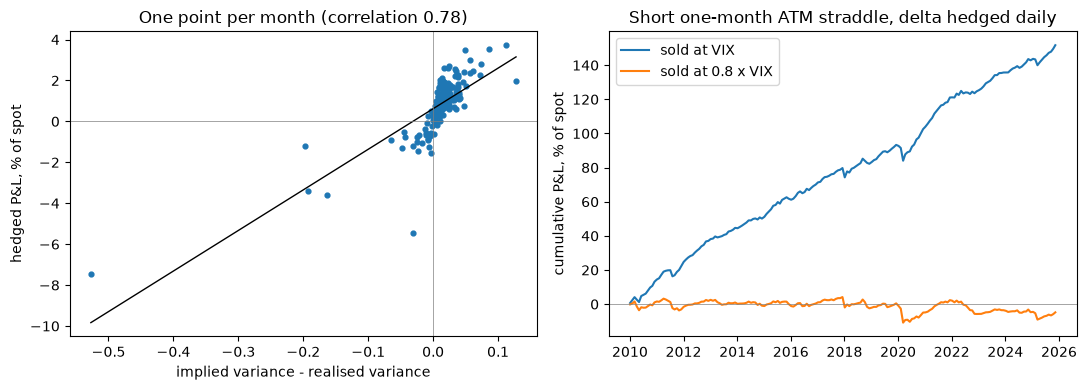

correlation between P&L and (implied - realised variance): 0.78, R2 = 0.61


In [8]:
x = trades["implied"] ** 2 - trades["realised"] ** 2
y = trades["pnl %"]
corr = np.corrcoef(x, y)[0, 1]
slope, intercept = np.polyfit(x, y, 1)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(x, y, s=12)
xs = np.linspace(x.min(), x.max(), 50)
axes[0].plot(xs, intercept + slope * xs, color="k", lw=1)
axes[0].axhline(0, color="grey", lw=0.5); axes[0].axvline(0, color="grey", lw=0.5)
axes[0].set_xlabel("implied variance - realised variance")
axes[0].set_ylabel("hedged P&L, % of spot")
axes[0].set_title(f"One point per month (correlation {corr:.2f})")

axes[1].plot(trades.index, trades["pnl %"].cumsum(), label="sold at VIX")
axes[1].plot(trades_atm.index, trades_atm["pnl %"].cumsum(), label="sold at 0.8 x VIX")
axes[1].axhline(0, color="grey", lw=0.5)
axes[1].set_ylabel("cumulative P&L, % of spot")
axes[1].set_title("Short one-month ATM straddle, delta hedged daily")
axes[1].legend()
plt.tight_layout()
plt.show()
print(f"correlation between P&L and (implied - realised variance): {corr:.2f}, R2 = {corr**2:.2f}")

## Conclusions

- On real SPY data the hedged P&L of each trade is driven by implied minus realised variance:
  the direction of the market does not matter once delta is hedged.
- Sold at the VIX level the strategy looks profitable, because VIX has usually been above realised
  volatility. Part of that gap is not available to an option seller: VIX sits above the
  at-the-money volatility, and with 0.8 x VIX most of the edge disappears.
- The losses are concentrated in a few months when realised volatility jumped (March 2020).

**Limitations:** implied volatility is approximated from VIX (no historical option prices), the
bid-ask spread of the options is ignored, SPY options are priced as European, and the hedge uses
closing prices only.